# Decision Tree and Random Forest
**Aim:** To implement Decision Tree and Random Forest classifiers and compare them.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

### Load data

In [2]:
wine = load_wine()
X = wine.data
y = wine.target

df = pd.DataFrame(X, columns=wine.feature_names)
df['target'] = y
print(df.head())
print(df.shape)

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

### Split data

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

### Decision Tree

Decision Tree accuracy: 0.9629629629629629
[[18  1  0]
 [ 0 21  0]
 [ 0  1 13]]


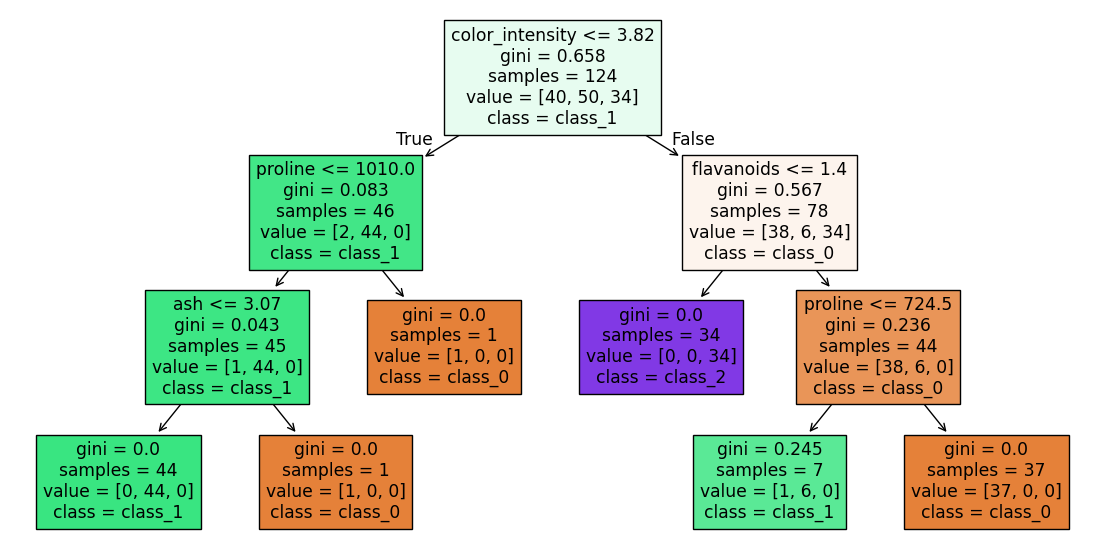

In [4]:
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

print("Decision Tree accuracy:", accuracy_score(y_test, dt_pred))
print(confusion_matrix(y_test, dt_pred))

plt.figure(figsize=(14,7))
plot_tree(dt, feature_names=wine.feature_names, class_names=wine.target_names, filled=True)
plt.show()

### Random Forest

In [5]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Random Forest accuracy:", accuracy_score(y_test, rf_pred))
print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred, target_names=wine.target_names))

Random Forest accuracy: 1.0
[[19  0  0]
 [ 0 21  0]
 [ 0  0 14]]
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        19
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        14

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



### Feature importance

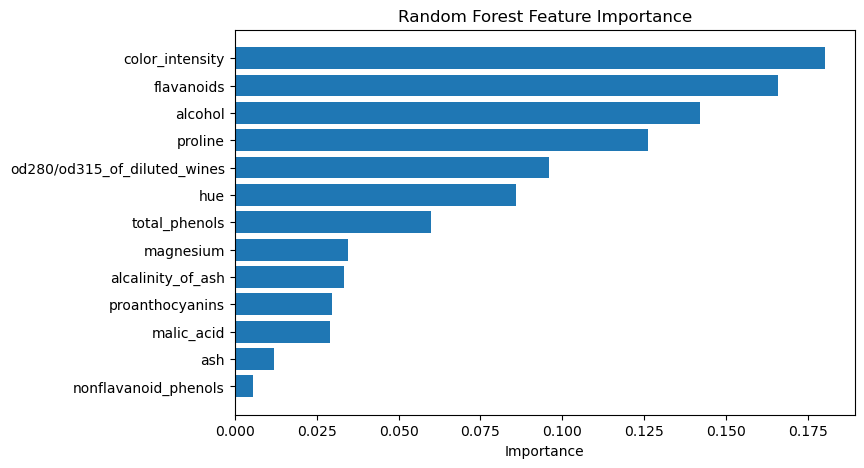

In [6]:
imp = rf.feature_importances_
idx = np.argsort(imp)

plt.figure(figsize=(8,5))
plt.barh(range(len(idx)), imp[idx])
plt.yticks(range(len(idx)), np.array(wine.feature_names)[idx])
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance")
plt.show()

### Compare both

In [7]:
print("Decision Tree:", accuracy_score(y_test, dt_pred))
print("Random Forest:", accuracy_score(y_test, rf_pred))

Decision Tree: 0.9629629629629629
Random Forest: 1.0


**Conclusion:** Decision Tree and Random Forest were implemented on the Wine dataset. Random Forest gave better accuracy than a single Decision Tree because it combines many trees. The feature importance graph shows which features matter most.